In [1]:
%load_ext autoreload
%autoreload 2

In [5]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

from pyprojroot import here

# Ajout de la racine au sys.path pour rendre les dossiers importables
root_dir = here()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from ann_playground.data import fetch_and_save_dataset

In [ ]:
# Load Data
output_dir = Path(root_dir) / "data" / "raw_data"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "data.csv"

if not output_path.is_file():
    dataset_id = 697
    df,X,y = fetch_and_save_dataset(dataset_id, output_path)

Note : on peut télécharger le fichier à l'adresse 
https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success

In [22]:
# Load Data
output_dir = Path(root_dir) / "data" / "raw_data"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "data.csv"

df = pd.read_csv(output_path, encoding='ascii')

In [23]:
df.head(5)

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
# Transforme l'index en une colonne classique nommée "id"
# df = df.reset_index().rename(columns={"index": "id"})

In [24]:
df.shape

(4424, 37)

<hr style="width: 50%; margin: 12px auto 0px auto;" />

# A. EDA

## 1. Encodage, Doublons, colonnes vides

In [6]:
import numpy as np
import pandas as pd
# from eda_utils import *

### 1a. Encodage
On vérifie l'encodage au tout début d'une EDA pour éviter de charger de la donnée corrompue sans s'en rendre compte.
- Si on essaie de lire un fichier encodé en latin-1 ou cp1252 en lui imposant du utf-8, Python plante immédiatement lors du pd.read_csv().
- Parfois, le fichier s'ouvre sans erreur, mais les caractères sont mal interprétés : Montréal devient MontrÃ©al

In [25]:
import unicodedata
import chardet

with open(output_path, 'rb') as file :
    encodage = chardet.detect(file.read(10000))

print(encodage)

{'encoding': 'ascii', 'confidence': 1.0, 'language': 'en', 'mime_type': 'text/plain'}


### 

### 1b. Analyse des doublons

In [26]:
cols_sans_id = [col for col in df.columns if col != 'id']
nb_doublons = df.duplicated(subset=cols_sans_id).sum()

if nb_doublons == 0:
    print("Aucun doublon trouvé dans le DataFrame.")
else :
    print(f"Nombre de doublons trouvés : {nb_doublons}\nAppelez la fonction duplicate_rows()")

Aucun doublon trouvé dans le DataFrame.


In [ ]:
# Nombre total de lignes en double
# df.duplicated().sum()

# Afficher toutes les lignes impliquées dans un doublon
# df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

# Doublons basés sur une ou plusieurs colonnes
# df[df.duplicated(subset=['id_client'], keep=False)]

# Garder la première occurrence et supprimer les autres
# df_clean = df.drop_duplicates()

# Ou modifier directement le DataFrame existant
# df.drop_duplicates(inplace=True)

### 1c. Colonnes vides

In [27]:
# Remplacer les espaces blancs ou chaînes "null" / "None" par np.nan
df_clean = df.replace(r'^\s*$', np.nan, regex=True).replace(['null', 'None', 'nan', 'N/A'], np.nan)

# Tableau récapitulatif des valeurs manquantes
na_summary = pd.DataFrame({
    'Manquants (count)': df_clean.isna().sum(),
    'Manquants (%)': (df_clean.isna().mean() * 100).round(2)
})

na_summary_filtered = na_summary[na_summary['Manquants (count)'] > 0]
if not na_summary_filtered.empty:
    print("Colonnes avec valeurs manquantes :")
    na_summary[na_summary['Manquants (count)'] > 0].sort_values(by='Manquants (%)', ascending=False)
else:
    print("Aucun colonne vide.")


Aucun colonne vide.


In [28]:
# Colonnes dont toutes les valeurs sont NaN"""
empty_columns = df.columns[df.isna().all()].tolist()

empty_columns

[]

In [11]:
df = df.dropna(axis=1, how='all')

In [29]:
# Colonnes contenant des valeurs manquantes explicites : NaN, None, '', 'na', 'null'
missing_vals = {np.nan, None, '', 'na', 'NA', 'null', 'NULL'}
cols = []
for col in df.columns:
    if df[col].isin(missing_vals).any():
        cols.append(col)
cols

[]

### 1d. Contrôle et harmonisation des types de données

In [30]:
df.info()
# df.dtypes ou df.info(), puis conversion avec pd.to_datetime(), pd.to_numeric(), ou .astype('category').

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

## 2. Statistiques descriptives
Les statistiques descriptives dans une EDA permettent de résumer la forme, le centre et la dispersion de tes données pour repérer immédiatement les anomalies, les asymétries ou les valeurs aberrantes.

In [32]:
df.describe(include='all')

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Graduate
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2209
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969,NaN
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935,NaN
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000,NaN
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000,NaN
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000,NaN
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000,NaN


1. Mesures de tendance centrale (Où se situe le milieu ?)  
    - Moyenne vs Médiane : La différence entre les deux t'indique la présence d'outliers.  
        Exemple : Si le salaire moyen est de $4\,500\text{ €}$ mais la médiane est à $2\,100\text{ €}$, cela signifie que quelques très hauts salaires tirent la moyenne vers le haut.
    - Mode : La valeur la plus fréquente (très utile pour les variables catégorielles ou discrètes).

2. Mesures de dispersion (Comment les données s'étalent-elles ?)  
    - Écart-type (Standard Deviation) & Variance : Mesurent la distance moyenne des points par rapport à la moyenne.
    - Min et Max : Permettent de vérifier les limites physiques/métier (ex. un âge min de $-5$ ou max de $300$ indique une erreur de saisie).
    - Quartiles ($Q1$, $Q2$/Médiane, $Q3$) & Ecart Interquartile ($IQR = Q3 - Q1$) : L'$IQR$ donne la plage où se trouvent les $50\%$ centraux des données (très robuste aux outliers).

3. Mesures de forme de la distribution  
    - Asymétrie (Skewness) :  
    $>0$ : étalée vers la droite (beaucoup de petites valeurs, quelques très grandes).  
    $<0$ : étalée vers la gauche.
    - Aplatissement (Kurtosis) : Indique si les valeurs sont très concentrées autour de la moyenne ou si les "queues" de distribution sont épaisses (présence fréquente d'outliers).

### 2a. variables numériques et variables catégorielles

La distinction entre numériques et catégorielles est un point clé : il y a énormément de variables catégorielles qui sont encodées sous forme de nombres entiers (par exemple, le mode d'application, le statut marital, les qualifications des parents, etc.). Si on ne les redéfinit pas proprement, Pandas les traite toutes comme du numérique.

In [51]:
df.columns

Index(['Marital Status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd s

In [41]:
# Identifier le nombre de valeurs uniques 
df.nunique().sort_values()

# df['colonne'].value_counts()
# df['colonne'].str.strip().str.lower()

Daytime/evening attendance                          2
Displaced                                           2
Debtor                                              2
Educational special needs                           2
International                                       2
Scholarship holder                                  2
Gender                                              2
Tuition fees up to date                             2
Target                                              3
Marital Status                                      6
Application order                                   8
Inflation rate                                      9
Curricular units 2nd sem (without evaluations)     10
Unemployment rate                                  10
GDP                                                10
Curricular units 1st sem (without evaluations)     11
Course                                             17
Previous qualification                             17
Application mode            

- Les binaires et catégorielles déguisées en entiers (ex: Marital Status, Gender, Debtor, Course, etc., de 2 à ~46 valeurs max).

- Les vraies continues / notes / scores (ex: Admission grade, notes des semestres, avec des centaines de valeurs uniques).

- Les macro-économiques (Inflation rate, Unemployment rate, GDP, qui ont une faible cardinalité mais sont bien continues).

### 2b. Histogrammes : Variables continues
Pour les vraies variables continues (Admission grade, notes des semestres, PIB, etc.), ils ont un grand intérêt. Ces histogrammes permettent de repérer :
- Des valeurs aberrantes (ex: une note à 200 au lieu de 20).
- L'asymétrie (skewness) des distributions, ce qui t'aide à comprendre si certaines données nécessitent une transformation (comme un log) avant d'être passées dans le modèle.
- L'échelle globale des valeurs.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict, Tuple, Optional, Any, List, Iterable
import math

def plot_numeric_histograms(
    X: pd.DataFrame,
    bins: int = 40,
    n_cols: int = 3,
    figsize_per_col: Tuple[int, int] = (5, 3),
) -> None:
    """
    Affiche les histogrammes de toutes les colonnes numériques.

    Parameters
    ----------
    X : pd.DataFrame
        Données d'entrée.
    bins : int
        Nombre de bins pour les histogrammes.
    n_cols : int
        Nombre de graphes par ligne.
    figsize_per_col : tuple
        Taille d'un subplot (largeur, hauteur).
    """
    num_cols = X.select_dtypes(include=["number"]).columns
    n_plots = len(num_cols)
    if n_plots == 0:
        return
    n_rows = math.ceil(n_plots / n_cols)
    plt.figure(figsize=(n_cols * figsize_per_col[0], n_rows * figsize_per_col[1]))
    for i, col in enumerate(num_cols, 1):
        plt.subplot(n_rows, n_cols, i)
        sns.histplot(X[col].dropna(), bins=bins)
        plt.xlabel("")   # masque axe X
        plt.ylabel("")   # masque axe Y
        plt.grid(True, alpha=0.3)
        plt.title(col)
    plt.tight_layout()
    plt.show()

In [44]:
feature_names = [
    'Previous qualification (grade)',
    'Admission grade',
    'Curricular units 2nd sem (grade)',
    'Curricular units 1st sem (grade)',
    'Inflation rate',
    'Unemployment rate',
    'GDP'
]

# Train DataFrame
df_numerique = pd.DataFrame(df, columns=feature_names)

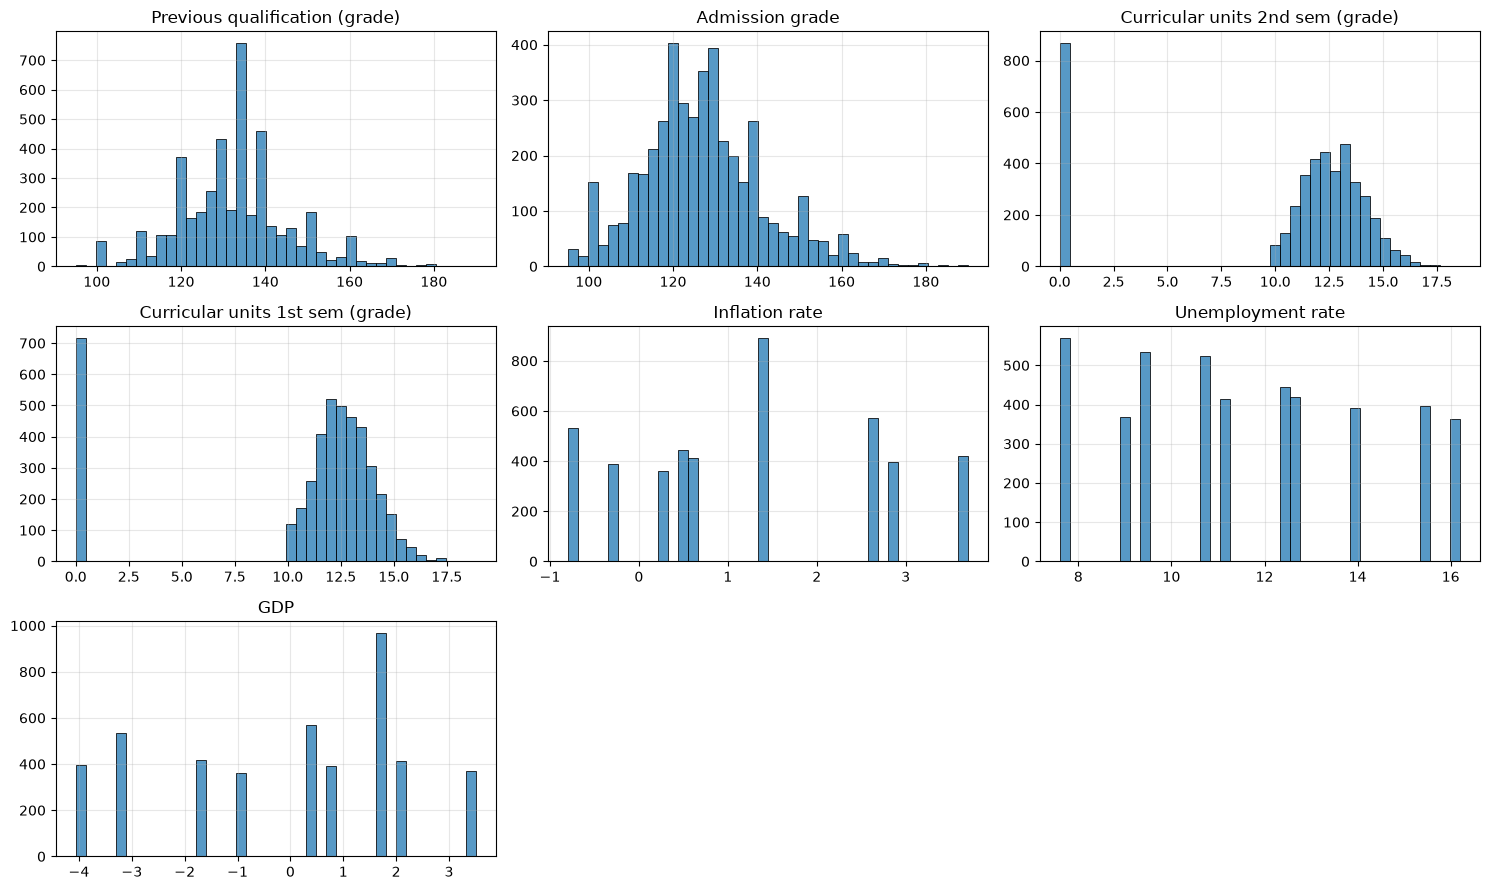

In [45]:
plot_numeric_histograms(df_numerique, bins=40, n_cols=3)

- Previous qualification et Admission grade ont des distributions globalement gaussiennes (avec une légère asymétrie à droite).

- Inflation rate, Unemployment rate, GDP) se comportent comme des variables discrètes ou catégorisées dans ce dataset (avec des valeurs fixes en fonction de la période d'inscription) : ce ne sont pas des lois continues classiques, mais cela reste tout à fait gérable pour un StandardScaler.

- Les notes des semestres 1 et 2 ont un pic massif à 0, qui représente probablement les étudiants qui n'ont pas eu d'évaluation ou qui ont abandonné.

a. Pour un MLP, on ne peut laisser ces 0 bruts sans distinction, ce qui fausserait complètement le scaling.

In [46]:
# Pour le 1er semestre
df['Sem1_grade_missing'] = (df['Curricular units 1st sem (grade)'] == 0).astype(int)

# Pour le 2ème semestre
df['Sem2_grade_missing'] = (df['Curricular units 2nd sem (grade)'] == 0).astype(int)

- On remplace le 0 par un NaN

In [47]:
df['Curricular units 1st sem (grade)'] = df['Curricular units 1st sem (grade)'].replace(0, float('nan'))
df['Curricular units 2nd sem (grade)'] = df['Curricular units 2nd sem (grade)'].replace(0, float('nan'))

b. Pour gérer proprement ces NaN créés artificiellement sans perturber ton modèle, la bonne pratique avec scikit-learn est d'utiliser un Pipeline ou d'enchaîner deux briques indispensables : un SimpleImputer (pour remplacer les NaN par une valeur de référence comme la médiane) et un StandardScaler (pour normaliser les données).

In [48]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# 1. Définition de tes colonnes continues (avec les notes nettoyées contenant des NaN)
continuous_cols = [
    'Previous qualification (grade)', 
    'Admission grade', 
    'Curricular units 1st sem (grade)', 
    'Curricular units 2nd sem (grade)', 
    'Inflation rate', 
    'Unemployment rate', 
    'GDP'
]

# 2. Création d'un sous-pipeline pour les variables continues : 
# On impute les NaN par la médiane, puis on applique le StandardScaler
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 3. Application via un ColumnTransformer pour ne traiter que les colonnes continues
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, continuous_cols)
    ],
    remainder='passthrough' # Garde les autres colonnes (catégorielles et indicateurs _missing) intactes
)

### 2c. Variables catégorielles : One-Hot Encoding
L'objectif est d'éviter que le réseau de neurones (le MLP) ne suppose un ordre ou une distance mathématique entre les catégories (par exemple, que la catégorie 4 soit "plus grande" que la catégorie 2, ce qui n'a aucun sens pour le statut marital ou le genre).

Le One-Hot Encoding transforme chaque variable catégorisée en plusieurs colonnes binaires (0 ou 1).

In [50]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# 1. Liste de tes variables catégorielles (le reste de ton dataset)
categorical_cols = [
    'Marital Status', 'Application mode', 'Application order', 'Course',
    'Daytime/evening attendance', 'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification", "Mother's occupation",
    "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment',
    'International'
]

# 2. Configuration du transformateur pour les catégorielles
# handle_unknown='ignore' évite les erreurs si de nouvelles catégories apparaissent dans le jeu de test
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# 3. Intégration complète dans le ColumnTransformer (Continu + Catégoriel + Indicateurs de notes manquantes)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, continuous_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='passthrough' # Laisse intacts les indicateurs _missing créés plus tôt
)

## 3. Corrélation

### 3a. On regarde la matrice de corrélation des variables continues avant de toucher au train/test split ou au reste du pipeline.

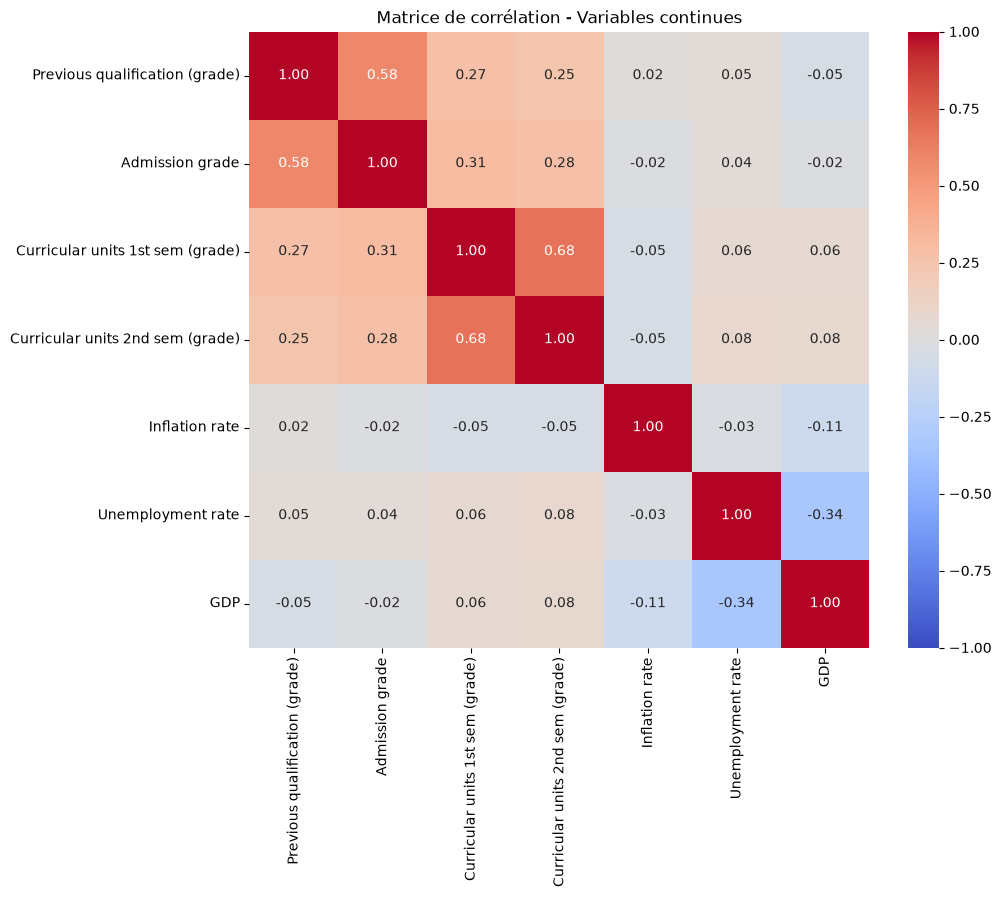

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

# Tes variables continues (incluant les notes nettoyées)
continuous_cols = [
    'Previous qualification (grade)', 
    'Admission grade', 
    'Curricular units 1st sem (grade)', 
    'Curricular units 2nd sem (grade)', 
    'Inflation rate', 
    'Unemployment rate', 
    'GDP'
]

# Affichage de la matrice de corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(df[continuous_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title("Matrice de corrélation - Variables continues")
plt.show()

Cette matrice de corrélation apporte des enseignements très clairs et rassurants pour la suite :
- La cohérence académique :
    - On observe une forte corrélation (0.68) entre les notes du 1er semestre et celles du 2ème semestre. C'est tout à fait logique : un étudiant qui performe au premier semestre a tendance à faire de même au second.
    - La note de qualification précédente et la note d'admission sont également bien corrélées (0.58), ce qui valide la continuité du parcours scolaire de l'étudiant.   
- L'indépendance des facteurs macro-économiques :
    - Les variables comme l'inflation, le chômage et le PIB affichent des corrélations quasi nulles avec les notes des étudiants (proches de 0). C'est une excellente nouvelle pour un MLP : ces variables macro-économiques apportent une information complémentaire et non redondante par rapport aux notes scolaires.
    - On note juste une corrélation négative classique entre le chômage et le PIB (-0.34), ce qui reflète des réalités économiques habituelles mais ne pose aucun problème de colinéarité excessive.
    
Aucune corrélation n'atteint des sommets aberrants (pas de $0.95$ ou $0.99$), ce qui signifie qu'on n'a pas besoin de supprimer de variables à cause d'une multicolinéarité destructive pour le réseau de neurones.

### 3b. Corrélation des variables catégorielles avec la cible

Pour mesurer l'association entre variables catégorielles et une cible catégorielle, on utilise principalement deux approches complémentaires :

##### → Le test statistique du $\chi^2$ (Chi-deux d'indépendance)
- Le test du Chi-deux compare la distribution observée des catégories à ce qu'on obtiendrait si la variable n'avait aucun lien avec la cible.
    - P-value $< 0.05$ : La variable a une relation statistiquement significative avec le statut de l'étudiant.
    - V de Cramér : Donne l'intensité de cette relation (entre 0 = aucun lien, et 1 = lien parfait).

In [53]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

categorical_cols = [
    'Marital Status', 'Application mode', 'Application order', 'Course',
    'Daytime/evening attendance', 'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification", "Mother's occupation",
    "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment',
    'International', 'Sem1_grade_missing', 'Sem2_grade_missing'
]

results = []

for col in categorical_cols:
    # Table de contingence entre la variable et la cible
    contingency_table = pd.crosstab(df[col], df['Target'])
    
    # Test du Chi-deux
    chi2, p_val, dof, _ = chi2_contingency(contingency_table)
    
    # Calcul du V de Cramér
    n = contingency_table.sum().sum()
    r, k = contingency_table.shape
    cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
    
    results.append({
        'Variable': col,
        'Chi2': round(chi2, 2),
        'p-value': p_val,
        'Cramers_V': round(cramers_v, 3)
    })

# Dataframe de résultats trié par force d'association
cramer_df = pd.DataFrame(results).sort_values(by='Cramers_V', ascending=False)
print(cramer_df.to_string(index=False))

                  Variable    Chi2       p-value  Cramers_V
        Sem2_grade_missing 1324.35 2.642840e-288      0.547
        Sem1_grade_missing  891.06 3.221466e-194      0.449
   Tuition fees up to date  823.55 1.471628e-179      0.431
        Scholarship holder  409.94  9.593930e-90      0.304
                    Course  558.28  2.316571e-97      0.251
         Age at enrollment  547.27  1.119506e-66      0.249
                    Debtor  259.33  4.858552e-57      0.242
                    Gender  233.27  2.222480e-51      0.230
          Application mode  466.51  1.964657e-77      0.230
       Mother's occupation  291.92  1.630859e-31      0.182
       Father's occupation  264.50  4.515439e-19      0.173
    Father's qualification  225.00  3.175007e-19      0.159
    Previous qualification  219.68  7.160305e-30      0.158
    Mother's qualification  217.95  5.823844e-21      0.157
                 Displaced   57.75  2.876311e-13      0.114
         Application order   69.61  2.27

- Les nouvelles variables sont les plus prédictives : 

    - Sem2_grade_missing ($V = 0.547$) et Sem1_grade_missing ($V = 0.449$) arrivent en tête de tout le dataset. Avoir identifié et isolé ce pic à 0 a créé les deux indicateurs catégoriels les plus puissants pour prédire le statut de l'étudiant.

    - Les variables financières et de profil sont très fortes : Tuition fees up to date ($0.431$), Scholarship holder ($0.304$), Course ($0.251$), Age at enrollment ($0.249$) et Debtor ($0.242$) apportent une information très lourde.

    - Les variables à faible signal : En bas du tableau, Nacionality ($p = 0.242$), International ($p = 0.527$) et Educational special needs ($p = 0.725$) ont une $p$-value $> 0.05$. Elles n'ont pas de lien statistiquement significatif avec la variable cible.

- Décision sur les variables non significatives :

    - Dans un premier temps, garde tout. Un réseau de neurones (MLP) est capable de mettre des poids proches de zéro sur les variables inutiles lors du passage de la rétropropagation.

    - Plus tard, si tu cherches à alléger le modèle ou réduire l'overfitting, tu pourras envisager de supprimer International, Educational special needs et Nacionality.

##### → La visualisation par empilement (Proportions par classe)
- Pour les variables catégorielles avec un fort V de Cramér, le plus parlant visuellement est d'afficher la proportion de Dropout, Enrolled et Graduate pour chaque modalité.

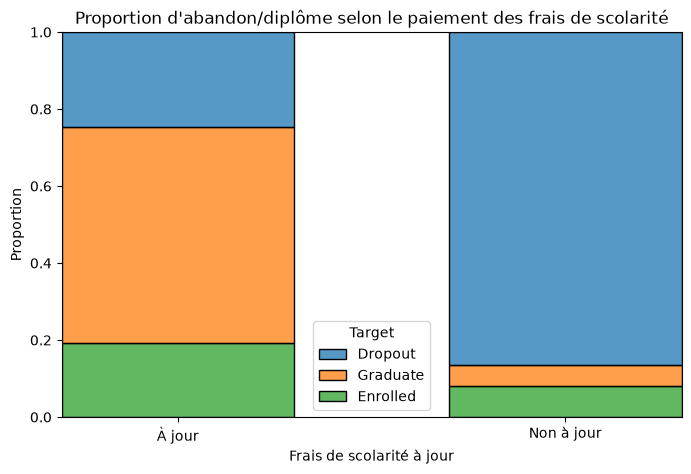

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

# Option 1 : Transformer en texte pour l'affichage
df_temp = df.copy()
df_temp['Tuition fees status'] = df_temp['Tuition fees up to date'].map({0: 'Non à jour', 1: 'À jour'})

plt.figure(figsize=(8, 5))
sns.histplot(
    data=df_temp, 
    x='Tuition fees status', 
    hue='Target', 
    multiple='fill', 
    stat='probability',
    shrink=0.6
)
plt.title("Proportion d'abandon/diplôme selon le paiement des frais de scolarité")
plt.ylabel("Proportion")
plt.xlabel("Frais de scolarité à jour")
plt.show()

- Ce graphique met en lumière un indicateur d'une puissance redoutable pour ton modèle :
 
    - Pour les étudiants « À jour » dans leurs frais (colonne de gauche) : La grande majorité obtient son diplôme (Graduate en orange) ou reste activement inscrite (Enrolled en vert), tandis que l'abandon y est minoritaire.   
    
    - Pour les étudiants « Non à jour » (colonne de droite) : C'est un basculement total. La quasi-totalité de la barre est bleue, ce qui montre qu'un défaut de paiement des frais de scolarité est presque systématiquement associé à un abandon (Dropout).   
    
- C'est exactement pour cela que cette variable affichait un V de Cramér aussi élevé (0.431) : pour un réseau de neurones (MLP), c'est une balise d'une clarté absolue qui va grandement l'aider à tracer ses frontières de décision.

<hr style="width: 50%; margin: 12px auto 0px auto;" />

# Multi-Layer Perceptron : using Keras

## 1. Préparation des données

In [69]:
from typing import Union

def plot_qualitative(
    X: Union[pd.DataFrame, pd.Series], # Accepte les deux types
    top_n: int = 20,
    n_cols: int = 2,
    figsize_per_col: Tuple[int, int] = (6, 4),
    figsize: Optional[Tuple[int, int]] = None,
    height_per_row: int = 4,
) -> None:
    
    # Conversion si c'est une Series
    if isinstance(X, pd.Series):
        # On donne un nom par défaut si la série n'en a pas
        name = X.name if X.name else "Target"
        X = X.to_frame(name=name)

    """
    Affiche des barplots pour les colonnes qualitatives.

    Parameters
    ----------
    X : pd.DataFrame ou pd.series
        Données d'entrée.
    top_n : int
        Nombre de modalités affichées par colonne.
    n_cols : int
        Nombre de graphes par ligne.
    figsize_per_col : tuple
        Taille d'un subplot (largeur, hauteur).
    """
    cat_cols = X.select_dtypes(include=["object", "category", "string", "bool"]).columns
    n_plots = len(cat_cols)
    if n_plots == 0:
        return

    n_rows = math.ceil(n_plots / n_cols)
    if figsize is None:
        figsize = (n_cols * figsize_per_col[0], n_rows * height_per_row)

    plt.figure(figsize=figsize)
    

    for i, col in enumerate(cat_cols, 1):
        plt.subplot(n_rows, n_cols, i)
        vc = X[col].astype("string").value_counts(dropna=False).head(top_n)
        sns.barplot(x=vc.values, y=vc.index, color="#439cc8")
        plt.xlabel("")
        plt.ylabel("")
        plt.title(col)
        plt.grid(True, axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

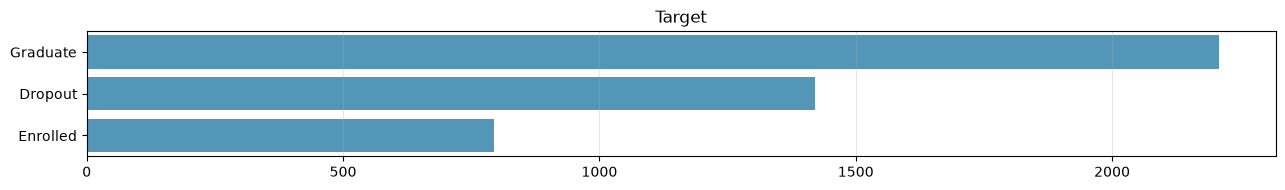

Pourcentage de Graduate : 49.93%
Pourcentage de Dropout : 32.12%
Pourcentage de Enrolled : 17.95%


In [70]:
plot_qualitative(df["Target"].astype("category"), n_cols=2, figsize=(25, 2))

# Pourcentage de "1" sur l'ensemble des observations
for valeur in ("Graduate","Dropout","Enrolled"):
    pourcentage_1 = (df["Target"].eq(valeur).mean()) * 100
    print(f"Pourcentage de {valeur} : {pourcentage_1:.2f}%")

### 1a. Encodage de la Target en int

On transforme les textes (Dropout, Enrolled, Graduate) en entiers (0, 1, 2) pour que le split et les algorithmes puissent les manipuler :

In [57]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df['Target'])

# On isole les features (X) en retirant la cible d'origine
X = df.drop(columns=['Target']).reset_index(drop=True)

### 1b. Train / Test Split (avec stratification)

Maintenant que y est prêt, on coupe les données en s'assurant de conserver les mêmes proportions de classes dans le train et le test :

In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 1c. Application du ColumnTransformer sur les Features (X)

Si on fait le fit sur l'ensemble des données (train + test confondus) :
- Les statistiques calculées (moyennes, médianes, écarts-types) intègrent des informations provenant du jeu de test (X_test).
- Par conséquent, le jeu d'entraînement (X_train) va indirectement "connaître" la distribution du jeu de test. C'est de là vient la fuite (leakage) : le futur se retrouve caché dans le passé.

    - fit_transform uniquement sur X_train : Le préprocesseur apprend les statistiques en analysant X_train, et il les applique immédiatement pour transformer X_train.
    - transform (uniquement) sur X_test : utilise uniquement les statistiques qui sont déjà enregistrées en mémoire (celles apprises lors du fit sur le train) pour les appliquer à X_test.

Note : Cette mémoire se trouve dans la mémoire vive (la RAM), stockée directement à l'intérieur de l'objet Python du transformateur (le StandardScaler ou le SimpleImputer). Quand on appelle .fit(X_train), le transformateur calcule les statistiques et les enregistre sous forme d'attributs (des variables internes) rattachés à cet objet.
- scaler.mean_ : un tableau NumPy qui contient la moyenne de chaque colonne calculée sur le train.
- scaler.scale_ : un tableau NumPy qui contient l'écart-type de chaque colonne.

C'est uniquement grâce à ces tableaux stockés en interne que, lorsque tu appelles ensuite .transform(X_test), le transformateur sait quoi soustraire et diviser.

In [59]:
# .fit_transform() uniquement sur le train
X_train_prep = preprocessor.fit_transform(X_train)

# .transform() uniquement sur le test
X_test_prep = preprocessor.transform(X_test)

### 1d. Sauvegarde

On utilise le format .pkl (via la bibliothèque joblib) parce qu'ils ne sont plus de simples DataFrames pandas, mais des tableaux NumPy (ou matrices) issus du ColumnTransformer.
Le format Pickle/Joblib est idéal dans ce cas :

- Préservation de la structure : Un tableau NumPy ou une matrice transformée possède des dimensions (shape) et des types de données spécifiques. Le format .pkl sérialise l'objet Python « tel quel » en mémoire binaire, ce qui garantit qu'en le rechargeant, tu retrouves exactement le même objet, sans perte d'information ni conversion tordue.

- Incompatibilité de formats tabulaires purs : Des formats comme CSV ou Parquet sont parfaits pour des DataFrames tabulaires avec des noms de colonnes explicites. Mais une fois que le ColumnTransformer est passé par là, tes données sont souvent transformées en un gros tableau NumPy brut (où les noms de colonnes d'origine disparaissent au profit d'indices de colonnes).

- Optimisation avec joblib : Pour les tableaux NumPy contenant beaucoup de données numériques, joblib est plus performant et plus rapide que le pickle standard de Python, car il gère très efficacement le stockage sur disque des grands blocs de mémoire.

In [86]:
from pathlib import Path
from pyprojroot import here
import joblib

# 1. Création du dossier data/clean_data s'il n'existe pas
clean_data_dir = here("data/clean_data")
clean_data_dir.mkdir(parents=True, exist_ok=True)

# 2. Sauvegarde du DataFrame complet (au format parquet, idéal pour les perfs et la compression)
df.to_parquet(clean_data_dir / "df.parquet", index=False)

# 3. Sauvegarde des matrices transformées et des cibles avec joblib
joblib.dump(X_train_prep, clean_data_dir / "X_train_prep.pkl")
joblib.dump(X_test_prep, clean_data_dir / "X_test_prep.pkl")
joblib.dump(y_train, clean_data_dir / "y_train.pkl")
joblib.dump(y_test, clean_data_dir / "y_test.pkl")

print(f"✅ Tous les fichiers ont été sauvegardés avec succès dans : {clean_data_dir}")

✅ Tous les fichiers ont été sauvegardés avec succès dans : /home/philippe/work-plateforme/05-ann-playground/data/clean_data


## 2. Multi-Layer Perceptron : using Keras

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
import pandas as pd
import joblib
from pyprojroot import here

clean_data_dir = here("data/clean_data")

df = pd.read_parquet(clean_data_dir / "df.parquet")
X_train_prep = joblib.load(clean_data_dir / "X_train_prep.pkl")
X_test_prep = joblib.load(clean_data_dir / "X_test_prep.pkl")
y_train = joblib.load(clean_data_dir / "y_train.pkl")
y_test = joblib.load(clean_data_dir / "y_test.pkl")

In [5]:
# Confusion Matrix
def get_confusion_matrix(model, X_test_prep, y_test):
    
    class_names = ['Dropout', 'Enrolled', 'Graduate']

    # 1. Obtenir les probabilités de prédiction sur le jeu de test
    y_pred_probs = model.predict(X_test_prep)

    # 2. Récupérer l'indice de la classe ayant la plus forte probabilité (0, 1 ou 2)
    y_pred_classes = np.argmax(y_pred_probs, axis=1)

    # 3. Calculer la matrice de confusion
    cm = confusion_matrix(y_test, y_pred_classes)

    # 4. Affichage graphique avec Seaborn
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues',
        xticklabels=class_names,  # Récupère les noms d'origine ('Dropout', 'Enrolled', 'Graduate')
        yticklabels=class_names
    )
    plt.title("Matrice de Confusion du MLP")
    plt.xlabel("Classe Prédite")
    plt.ylabel("Classe Réelle")
    plt.show()

    # 5. Afficher un rapport détaillé (Précision, Rappel, F1-score par classe)
    print("\nRapport de classification détaillé :")
    print(classification_report(y_test, y_pred_classes, target_names=class_names))

### 2a. Définition de l'architecture du réseau

- Pour un problème de classification tabulaire à 3 classes avec un nombre de colonnes transformées potentiellement élevé (à cause du One-Hot Encoding des variables catégorielles), une architecture classique à deux couches cachées fonctionne très bien :

In [ ]:
%pip install tensorflow

Les couches Dropout jouent un rôle crucial de régularisation dans le réseau de neurones.

1. Pendant la phase d'entraînement (fit), chaque couche de Dropout désactive aléatoirement un certain pourcentage de connexions (ou de neurones de la couche précédente) à chaque passage de données (batch). Avec un taux de dropout de 0.3, 30% des neurones sont "éteints" au hasard à chaque étape.

2. L'objectif principal est de combattre le surapprentissage (overfitting)
    - Empêcher la mémorisation par cœur : Sans dropout, les neurones peuvent parfois "s'entendre" entre eux et mémoriser par cœur les moindres détails du jeu d'entraînement (y compris le bruit).
    - Forcer la robustesse : Comme un neurone peut être éteint à tout moment de manière imprévisible, le réseau ne peut pas se reposer sur un seul chemin ou un seul neurone "favori". Il est obligé d'apprendre des représentations redondantes et généralisables, ce qui l'aide à être beaucoup plus performant sur de nouvelles données (le jeu de test).

3. Pendant l'évaluation ou la prédiction (inference) : Le Dropout est automatiquement désactivé. Tous les neurones restent actifs pour que le modèle puisse exploiter 100% de sa capacité.
    - C'est pour cela qu'elles affichent 0 paramètre dans ton tableau model.summary() : elles n'ont aucun poids (ni biais) à apprendre, elles agissent simplement comme un interrupteur aléatoire temporaire pendant la phase d'apprentissage.


In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

In [ ]:
# On initialise un conteneur de modèle séquentiel (vide pour l'instant)
model = Sequential()

#  On définit explicitement la forme de l'entrée avec Input
input_dim = X_train_prep.shape[1]
model.add(Input(shape=(input_dim,)))

# On ajoute la 1ère couche cachée (Dense) de 64 neurones + activation ReLU
model.add(Dense(64, activation='relu'))

# On ajoute un Dropout pour éteindre 30% des neurones de la couche précédente au hasard
model.add(Dropout(0.3))

#  On ajoute la 2ème couche cachée (Dense) plus compacte de 32 neurones + ReLU
model.add(Dense(32, activation='relu'))

# On ajoute un second Dropout (20% de désactivation)
model.add(Dropout(0.2))

# On ajoute la couche de sortie finale (3 neurones pour nos 3 classes) + Softmax
model.add(Dense(3, activation='softmax'))

# Pour vérifier l'architecture finale obtenue :
model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_41 (Dense)                │ (None, 64)             │        19,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,315 (83.26 KB)

 Trainable params: 21,315 (83.26 KB)

 Non-trainable params: 0 (0.00 B)

In [68]:
X_train_prep.shape

(3539, 298)

### 2b. Compilation du modèle
On configure l'optimiseur (Adam est un standard robuste) et la fonction de perte adaptée à des cibles sous forme d'entiers :

In [69]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # Car y_train est un tableau d'entiers (0, 1, 2)
    metrics=['accuracy']
)

### 2c. Entraînement (Fit) avec suivi de validation

On réserve une portion du jeu d'entraînement (par exemple 20%) pour valider les performances à chaque époque (epoch) et surveiller l'apprentissage :

In [70]:
history = model.fit(
    X_train_prep, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0
)

### 2d. Évaluation finale sur le jeu de Test

In [71]:
test_loss, test_accuracy = model.evaluate(X_test_prep, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7333 - loss: 1.0254
Précision sur le jeu de test : 73.33%


### 2e. Matrice de Confusion

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


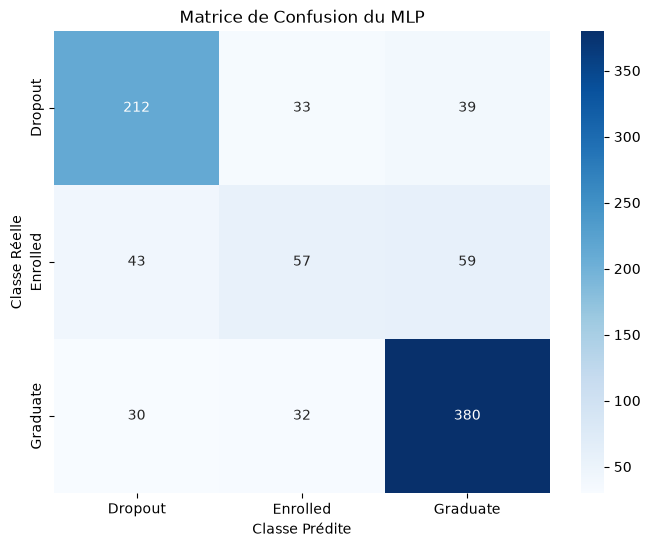


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.74      0.75      0.75       284
    Enrolled       0.47      0.36      0.41       159
    Graduate       0.79      0.86      0.83       442

    accuracy                           0.73       885
   macro avg       0.67      0.65      0.66       885
weighted avg       0.72      0.73      0.72       885



In [72]:
get_confusion_matrix(model, X_test_prep, y_test)

- Pour les diplômés (Graduate) : C'est la classe la mieux prédite. Le modèle est solide avec un F1-score de 0.83 (380 bons diagnostics sur 442). Lorsqu'il prédit qu'un étudiant va réussir, il a raison dans la grande majorité des cas.

- Pour les abandons (Dropout) : Les résultats sont honorables avec un F1-score de 0.75. Le modèle repère bien la tendance, même s'il y a un peu de confusion (46 étudiants en abandon ont été classés par erreur comme Enrolled et 35 comme Graduate).

- Pour les inscrits (Enrolled) : La classe Enrolled (étudiants toujours inscrits mais pas encore diplômés) est très mal capturée par le réseau de neurones : un rappel de 0.36 et une précision de 0.47 (F1-score de 0.41). Concrètement, sur 159 étudiants réellement Enrolled, le modèle n'en a bien identifié que 57. Il en a envoyé 43 dans la case Dropout et 59 dans la case Graduate.

### 2f. class_weight

Sans intervention, le modèle a tendance à « négliger » la classe minoritaire (Enrolled) car, mathématiquement, il peut obtenir une précision globale déjà correcte en se concentrant uniquement sur les deux classes majoritaires. L'optimiseur cherche à minimiser l'erreur globale, ce qui pénalise peu le modèle s'il se trompe sur les rares cas Enrolled.

Le principe est d'ajuster la pénalité (la fonction de perte / loss) en fonction de la fréquence de chaque classe :

- Classes majoritaires : Elles reçoivent un poids plus faible (ex: 0.7). Une erreur sur ces classes coûte "peu" au modèle.

- Classes minoritaires ou difficiles : Elles reçoivent un poids plus élevé (ex: 3.2). Une erreur sur ces classes est lourdement sanctionnée dans le calcul de l'erreur.

In [73]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Calculer les poids pour chaque classe en fonction de leur présence dans y_train
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Transformer le tableau en dictionnaire attendu par Keras (ex: {0: p0, 1: p1, 2: p2})
class_weight_dict = dict(enumerate(class_weights))

print("Poids des classes attribués :", class_weight_dict)

Poids des classes attribués : {0: np.float64(1.0375256523013778), 1: np.float64(1.857742782152231), 2: np.float64(0.6676098849273722)}


In [74]:
history = model.fit(
    X_train_prep, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    class_weight=class_weight_dict,  # <-- C'est ici que la magie opère
    verbose=0
)

In [85]:
test_loss, test_accuracy = model.evaluate(X_test_prep, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6938 - loss: 1.6781
Précision sur le jeu de test : 69.38%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


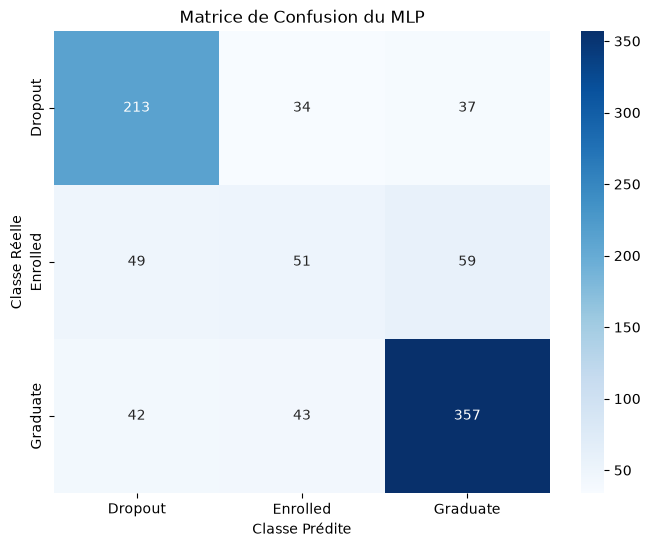


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.70      0.75      0.72       284
    Enrolled       0.40      0.32      0.36       159
    Graduate       0.79      0.81      0.80       442

    accuracy                           0.70       885
   macro avg       0.63      0.63      0.63       885
weighted avg       0.69      0.70      0.69       885



In [ ]:
get_confusion_matrix(model, X_test_prep, y_test)

## 3. Analyse en Composantes Principales

- Trouver le nombre idéal de n_components est un arbitrage classique entre conserver un maximum d'information et réduire la complexité des données pour éviter le surapprentissage.

#### 3a. La variance cumulée expliquée (La méthode standard)

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

Nombre de composantes nécessaire pour 95% de variance : 30


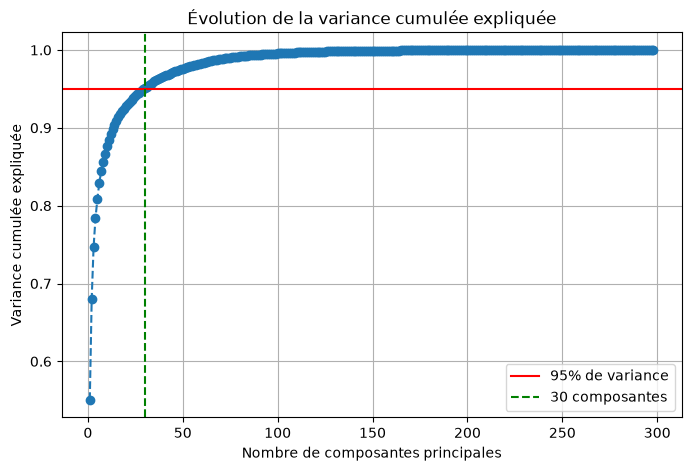

In [7]:
# Ajuster une PCA sans limite sur vos données d'entraînement prétraitées
pca_full = PCA(random_state=42)
pca_full.fit(X_train_prep)

# Calculer la variance cumulée expliquée
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Trouver automatiquement le nombre de composantes pour atteindre 95% de variance
threshold = 0.95
n_components_95 = np.argmax(cumulative_variance >= threshold) + 1
print(f"Nombre de composantes nécessaire pour {int(threshold*100)}% de variance : {n_components_95}")

# 4. Visualiser la courbe de la variance cumulée
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=threshold, color='r', linestyle='-', label=f'{int(threshold*100)}% de variance')
plt.axvline(x=n_components_95, color='g', linestyle='--', label=f'{n_components_95} composantes')

plt.xlabel('Nombre de composantes principales')
plt.ylabel('Variance cumulée expliquée')
plt.title('Évolution de la variance cumulée expliquée')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

- Avec seulement 30 composantes principales (repérées par la ligne verte), on parvient à conserver 95% de la variance totale de tes 298 variables d'origine (ligne rouge).

- Moins de bruit, plus d'efficacité : Cela signifie que tes 298 colonnes (largement gonflées par le One-Hot Encoding) contenaient beaucoup de redondance et de bruit. En passant à 30 dimensions, on élimine ce bruit superflu tout en conservant l'essentiel de l'information mathématique.

#### 3b. Méthode des éboulis

In [8]:
def scree_plot(pca, figsize=(10, 6)):

    # calcul de la variance epliquée et cumulée
    explained_variance = pca.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance)

    plt.figure(figsize=figsize)
    plt.bar(range(1, len(explained_variance) + 1),
            explained_variance, 
            alpha=0.5, align='center',
            label='Variance expliquée par composante', 
            color='#439cc8')
    
    # courbe de la variance expliquée cumulative
    plt.plot(range(1, len(cumulative_variance) + 1),
             cumulative_variance, 
             marker='o', linestyle='--',
             color='darkorange', 
             label='Variance expliquée cumulative')
    plt.xlabel('Composantes principales')
    plt.ylabel('Variance expliquée')
    plt.title('Ebouli des valeurs propres\n')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.show()

In [9]:
# PCA(), sans spécifier de nombre de composantes, garde toutes les composantes possibles, 
#  soit autant que de colonnes transformées.
pca_no_target = PCA()
X_pca_no_target = pca_no_target.fit_transform(X_train_prep)

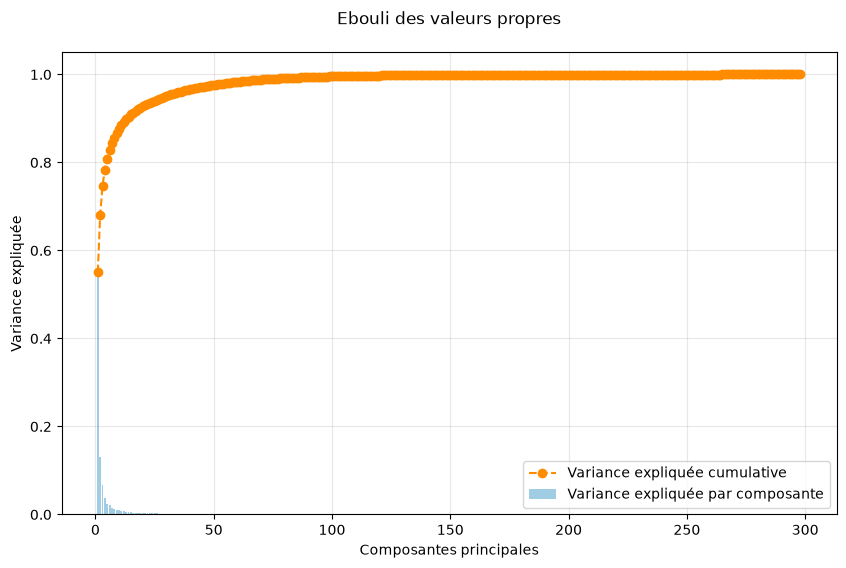

In [10]:
scree_plot(pca_no_target)

- Le graphique d'éboulis des valeurs propres complète le précédent et apporte une information visuelle sur la structure des données.

    - **La domination de la première composante** : La barre bleue tout à gauche montre que la toute première composante principale capte à elle seule plus de 50 % de la variance totale de ton jeu de données (environ 55 %). C'est énorme et cela indique qu'il existe un axe principal d'information très fort (probablement lié à la réussite ou au niveau académique global des étudiants).

    - **Le coude (elbow)** : La courbe orange (variance cumulée) grimpe de manière fulgurante sur les 10 à 20 premières composantes avant de former un plateau quasi horizontal.

    - **L'apport marginal des dimensions lointaines** : Passé un certain cap (autour de 30-50 composantes), chaque nouvelle composante n'apporte presque plus rien (les barres bleues deviennent quasi nulles).

#### 3c. Entraînement et évaluation

In [11]:
# Ajustement des données
pca = PCA(n_components=30)
X_train_pca = pca.fit_transform(X_train_prep)
X_test_pca = pca.transform(X_test_prep)

print("Nouvelle forme de X_train :", X_train_pca.shape)

Nouvelle forme de X_train : (3539, 30)


In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# 1. Définir la nouvelle dimension d'entrée
input_dim_pca = X_train_pca.shape[1]  # Vaut 30

# 2. Reconstruire le modèle avec cette nouvelle dimension
model_pca = Sequential([
    Input(shape=(input_dim_pca,)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

# 3. Compilation
model_pca.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Entraînement sur les données PCA
history_pca = model_pca.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0
)

In [84]:
test_loss, test_accuracy = model_pca.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7638 - loss: 0.6034
Précision sur le jeu de test : 76.38%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


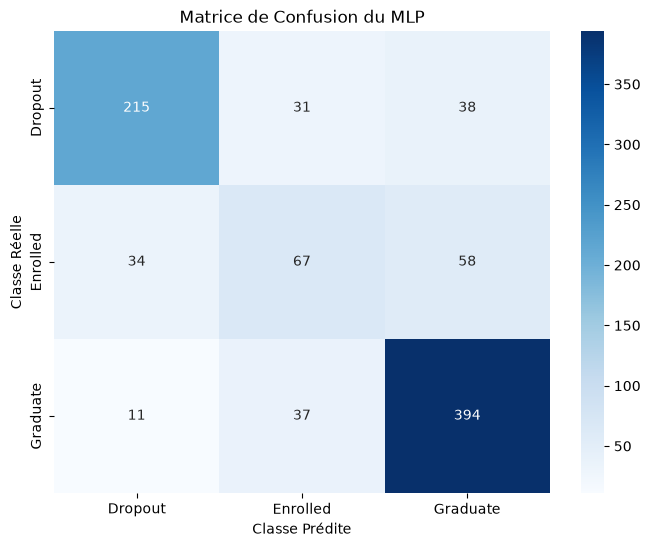


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.83      0.76      0.79       284
    Enrolled       0.50      0.42      0.46       159
    Graduate       0.80      0.89      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.69      0.70       885
weighted avg       0.76      0.76      0.76       885



In [82]:
get_confusion_matrix(model_pca, X_test_pca, y_test)

- La PCA à 30 dimensions a clairement joué son rôle : en éliminant le bruit des 298 variables initiales, le réseau de neurones respire mieux et généralise beaucoup plus proprement.

    - L'accuracy globale grimpe à 76.38% (contre de 69.38% à 73.33% précédemment).

- Le modèle est beaucoup plus stable sur les classes extrêmes :

    - Dropout passe à un F1-score de 0.79 (avec une précision de 0.883).

    - Graduate atteint un excellent F1-score de 0.85 avec un rappel de 0.89 (il rate très peu les étudiants qui réussissent).

    - Enrolled reste la plus difficile (ce qui confirme son chevauchement structurel inévitable), mais on observe tout de même un frémissement positif avec un F1-score qui remonte à 0.46 (et une précision qui passe à 0.50).


## 4. Différentes architectures de MLP

L'objet history renvoyé par la méthode .fit() de Keras stocke un dictionnaire (history.history) qui contient les clés 'loss' et 'val_loss', ainsi que 'accuracy' et 'val_accuracy', si l'on passe metrics=['accuracy'] lors de la compilation.

- Courbe d'entraînement et courbe de validation

    - La **courbe d'entraînement**  mesure l'erreur (la loss) du modèle calculée sur les données qu'il est en train d'apprendre (X_train_pca) : elle baisse presque toujours continuellement au fil des epochs. À chaque tour, le réseau ajuste ses poids pour mieux coller à ces exemples précis : si elle ne baissait pas, cela signifierait que le modèle n'apprend absolument rien.

    - La **courbe de validation** mesure l'erreur calculée sur un sous-ensemble de données de X_train que le modèle ne voit jamais pendant la mise à jour de ses poids (le jeu de validation, mis de côté via validation_split=0.2).

In [ ]:
import matplotlib.pyplot as plt

def plot_learning_curves(history, model_name="MLP"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. Courbe de la fonction de perte (Loss)
    ax1.plot(history.history['loss'], label='Entraînement', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Validation', linewidth=2, linestyle='--')
    ax1.set_title(f'Évolution de la Perte ({model_name})')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)
    
    # 2. Courbe de la précision (Accuracy)
    ax2.plot(history.history['accuracy'], label='Entraînement', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Validation', linewidth=2, linestyle='--')
    ax2.set_title(f'Évolution de la Précision ({model_name})')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()


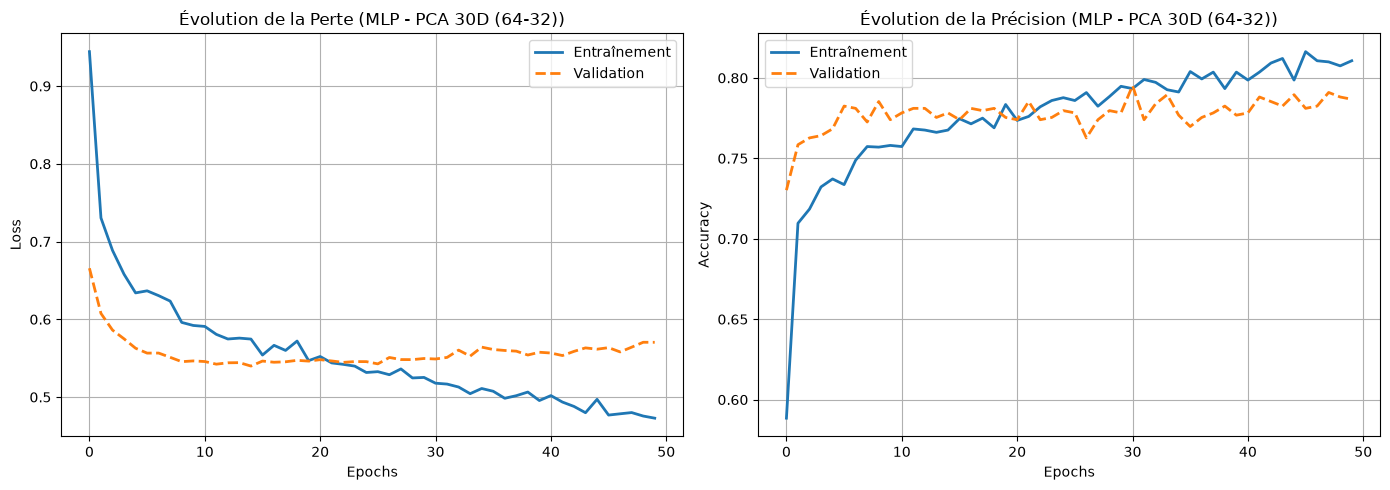

In [18]:
# Appel de la fonction pour ton modèle PCA actuel
plot_learning_curves(history_pca, model_name="MLP - PCA 30D (64-32)")

1. Evolution de la perte (loss)

    - **La phase d'apprentissage (de 0 à ~20 epochs)** : La perte d'entraînement (ligne bleue) et la perte de validation (ligne orange) chutent toutes les deux de manière très nette. Le modèle apprend rapidement et généralise bien.

    - **Le point optimal (autour de l'epoch 20 à 25)** : La perte de validation atteint son point le plus bas (autour de 0.54-0.55) et commence à se stabiliser.

    - **Le début de l'Overfitting (au-delà de 25 epochs)** : La perte d'entraînement continue de descendre pour atteindre ~0.49, mais la perte de validation stagne, voire remonte très légèrement pour se stabiliser autour de 0.55-0.56.
    

2. Evolution de la precision (accuracy)

    - La courbe de validation grimpe rapidement au début, puis atteint un plateau stable autour de 77 % à 79 % de précision dès les premiers epochs (notamment autour de l'epoch 15-20). Une fois ce plateau atteint, elle ne progresse plus du tout, oscillant horizontalement jusqu'à la fin des 50 epochs.

    - La courbe d'entraînement continue d'augmenter régulièrement pour dépasser les 81 % en fin de parcours : plus l'entraînement avance, plus le modèle devient performant sur les données qu'il connaît déjà (la courbe monte), mais cette performance supplémentaire ne profite pas aux données de validation (la courbe stagne). C'est la définition parfaite de l'overfitting : le modèle commence à apprendre du bruit spécifique au lieu de généraliser.

À partir de l'epoch 25, le réseau commence à mémoriser le bruit spécifique de ton jeu d'entraînement plutôt que d'extraire des règles générales, ce qui nuit à sa capacité à prédire de nouvelles données. Pour ce type de situation, on implémente un mécanisme d'Early Stopping susceptible de couper l'entraînement automatiquement.

In [87]:
from tensorflow.keras.callbacks import EarlyStopping

# On recrée le modèle à neuf (poids aléatoires initiaux)
model_pca = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

# On le recompile
model_pca.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Définition du callback d'arrêt précoce, et  Intégration dans le .fit() via le paramètre callbacks
early_stopping = EarlyStopping(
    monitor='val_loss',        # On surveille la perte sur les données de validation
    patience=5,                # Nombre d'epochs à attendre si la métrique ne s'améliore plus
    restore_best_weights=True  # Récupère automatiquement les meilleurs poids de l'epoch optimale
)

history_pca_2 = model_pca.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping], 
    verbose=0
)

Note : Si on appelle la méthode .fit() une deuxième fois sur la même instance de modèle (model_pca) sans le réinitialiser, Keras ne remet pas les poids à zéro, il reprend l'entraînement exactement là où il s'était arrêté à la fin des 50 epochs précédentes.

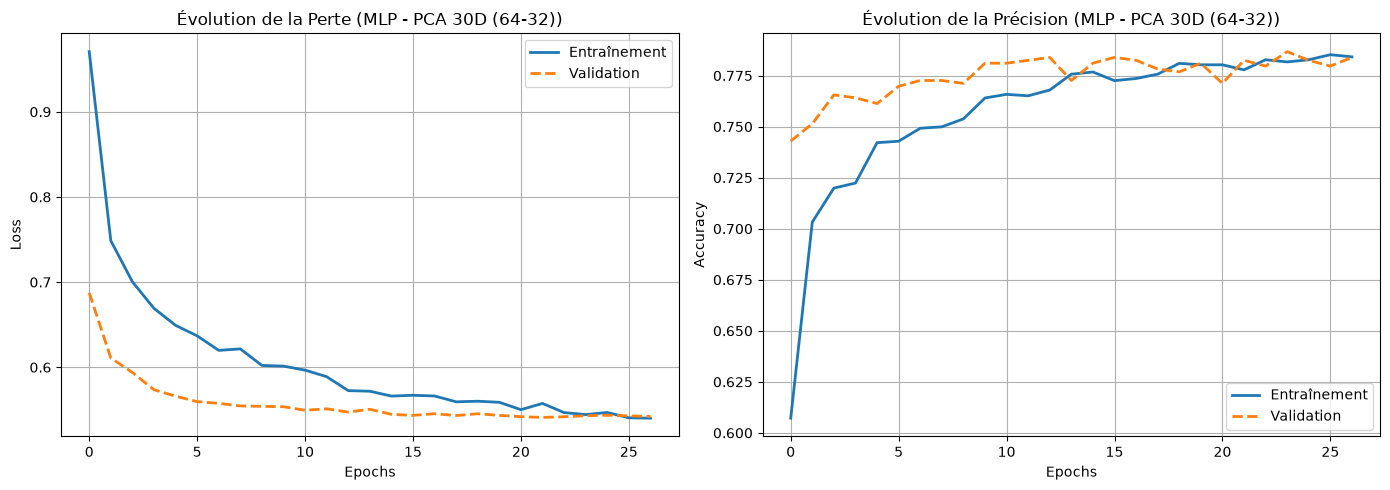

In [88]:
plot_learning_curves(history_pca_2, model_name="MLP - PCA 30D (64-32)")

#### 4a. Un réseau plus profond

In [92]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

model_deep = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(3, activation='softmax')
])

model_deep.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_deep = model_deep.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0  # Mode silencieux pour enchaîner
)
print("Modèle Profond entraîné avec succès !")

Modèle Profond entraîné avec succès !


In [93]:
test_loss, test_accuracy = model_deep.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7525 - loss: 0.6647
Précision sur le jeu de test : 75.25%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


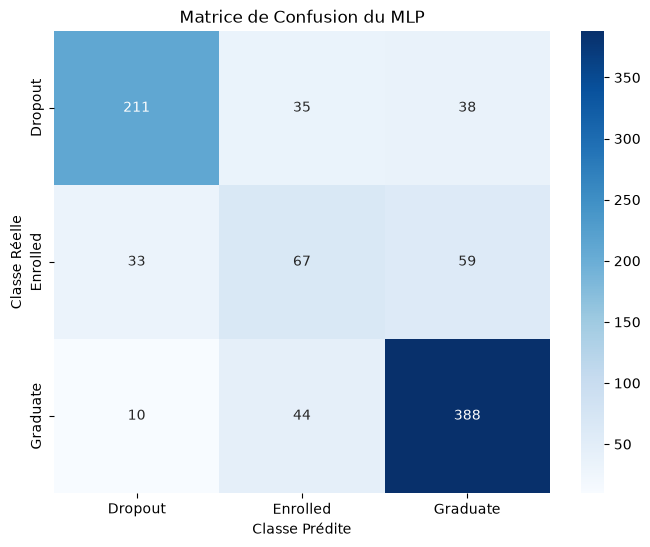


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.83      0.74      0.78       284
    Enrolled       0.46      0.42      0.44       159
    Graduate       0.80      0.88      0.84       442

    accuracy                           0.75       885
   macro avg       0.70      0.68      0.69       885
weighted avg       0.75      0.75      0.75       885



In [94]:
get_confusion_matrix(model_deep, X_test_pca, y_test)

L'ajout de profondeur dans l'architecture (Model_deep) n'explose pas l'accuracy générale, de 76,38% à 75.25% (ce qui est logique vu la difficulté de la classe Enrolled)

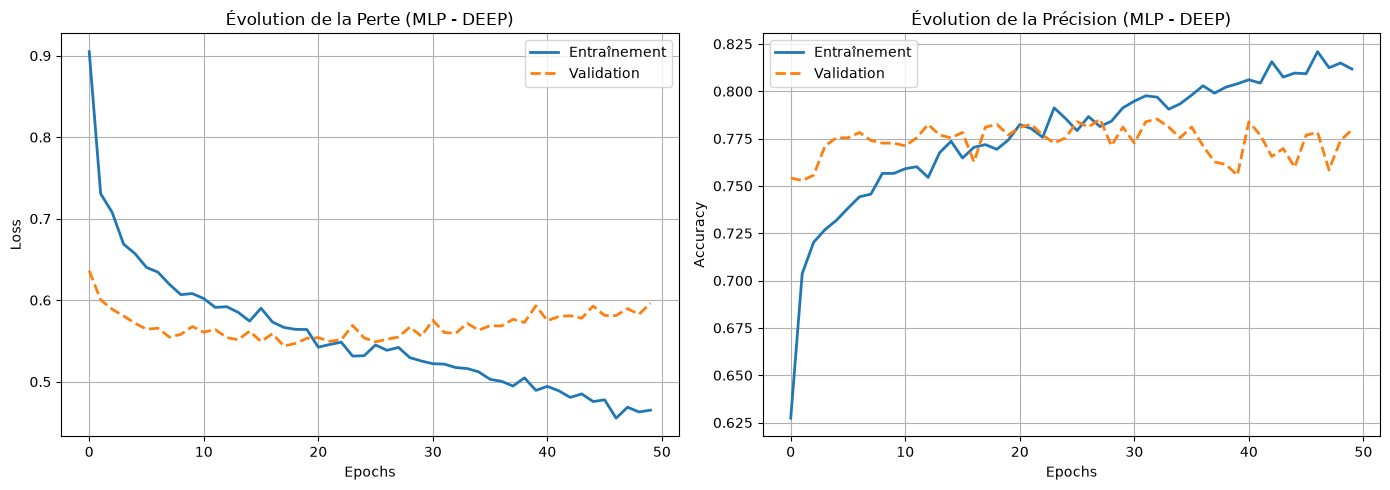

In [95]:
plot_learning_curves(history_deep, model_name="MLP - DEEP")

#### 4b. Un réseau plus large et régularisé (L2)

Le réseau ci-dessous fonctionne comme un entonnoir : il commence large pour capturer un maximum de combinaisons de caractéristiques, puis se resserre progressivement avant la décision finale.

- kernel_regularizer=l2(0.001) est un élément clé pour contrer le surapprentissage (overfitting), en particulier sur un réseau large qui a tendance à s'enflammer.

    - En terminologie Keras, le kernel désigne la matrice des poids synaptiques ($W$) qui relient les entrées aux neurones (hors biais).
    
    - Le l2(0.001) applique une régularisation de type Ridge (L2). Mathématiquement, il ajoute un terme de pénalité à la fonction de perte (loss) proportionnel à la somme des carrés des poids : $\text{Loss totale} = \text{Loss standard} + 0.001 \sum W^2$.
    
    - Il force ainsi le réseau à maintenir des poids de faibles valeurs. Il empêche qu'un ou deux neurones ne prennent une importance démesurée (ce qui arrive quand le modèle essaie d'apprendre du bruit par cœur). Cela lisse la fonction de décision globale et favorise la généralisation.


In [19]:
from tensorflow.keras.regularizers import l2

model_wide = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.4),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model_wide.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_wide = model_wide.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0
)
print("Modèle Large (L2) entraîné avec succès !")

Modèle Large (L2) entraîné avec succès !


In [20]:
test_loss, test_accuracy = model_wide.evaluate(X_test_pca, y_test)
print(f"Précision sur le jeu de test : {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7379 - loss: 0.8027
Précision sur le jeu de test : 73.79%


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


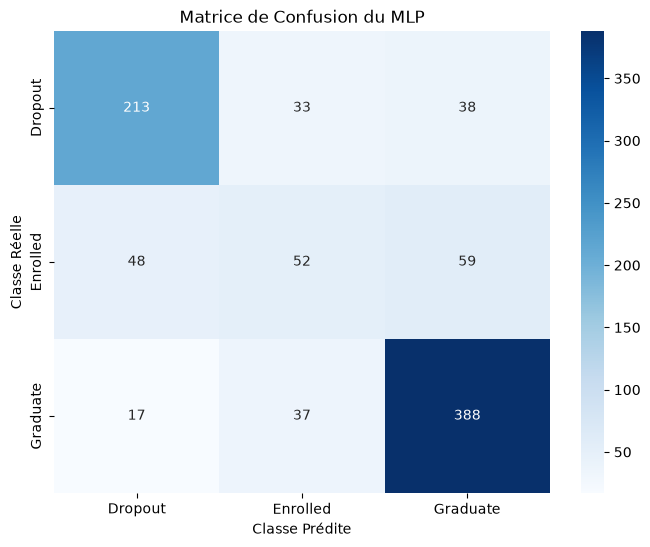


Rapport de classification détaillé :
              precision    recall  f1-score   support

     Dropout       0.77      0.75      0.76       284
    Enrolled       0.43      0.33      0.37       159
    Graduate       0.80      0.88      0.84       442

    accuracy                           0.74       885
   macro avg       0.66      0.65      0.66       885
weighted avg       0.72      0.74      0.73       885



In [21]:
get_confusion_matrix(model_wide, X_test_pca, y_test)

- Passer d'un réseau simple à des architectures plus profondes ou plus larges (avec régularisation L2) permet de grappiller quelques points précieux (notamment sur le rappel des Dropout et la captation des Enrolled), en faisant passer l'accuracy globale de 75.25% à 74.58%.

- Le rôle de la régularisation (L2) : Sur le modèle wide, l'ajout de pénalités L2 combiné au Dropout a permis de stabiliser l'apprentissage d'un réseau plus large sans tomber dans le piège du surapprentissage massif.

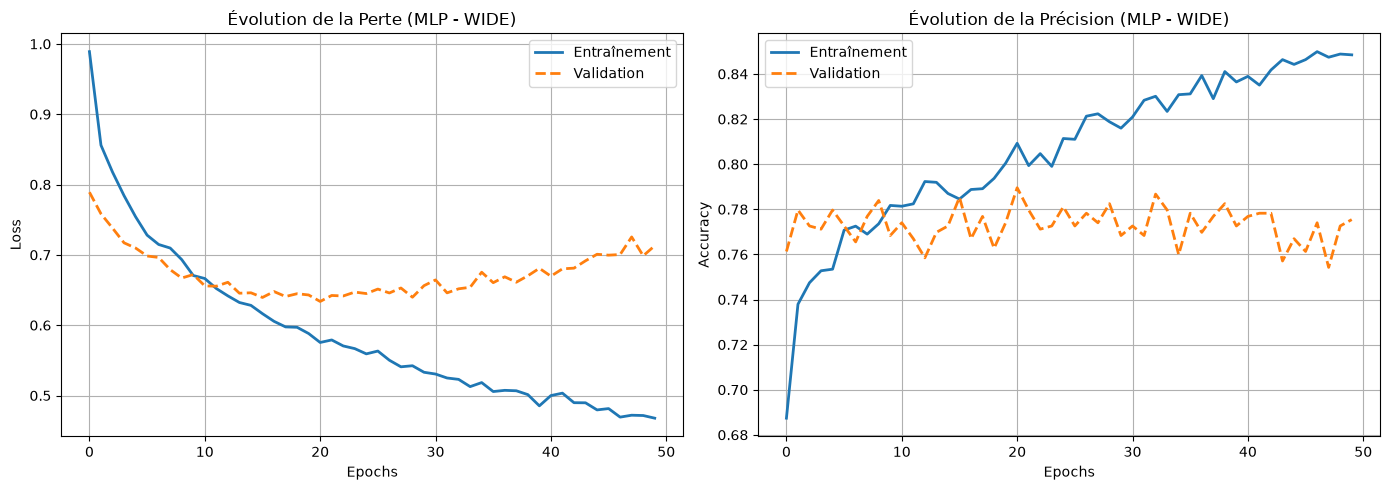

In [22]:
plot_learning_curves(history_wide, model_name="MLP - WIDE")

Étant plus large (plus de neurones), ce modèle a une puissance de calcul et de mémorisation bien supérieure. Il est donc normal qu'il « surchauffe » plus vite s'il n'est pas stoppé à temps.

In [24]:
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

model_wide = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.4),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

model_wide.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(
    monitor='val_loss',        # On surveille la perte sur les données de validation
    patience=3,                # Nombre d'epochs à attendre si la métrique ne s'améliore plus
    restore_best_weights=True  # Récupère automatiquement les meilleurs poids de l'epoch optimale
)

history_wide = model_wide.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping], 
    verbose=0
)

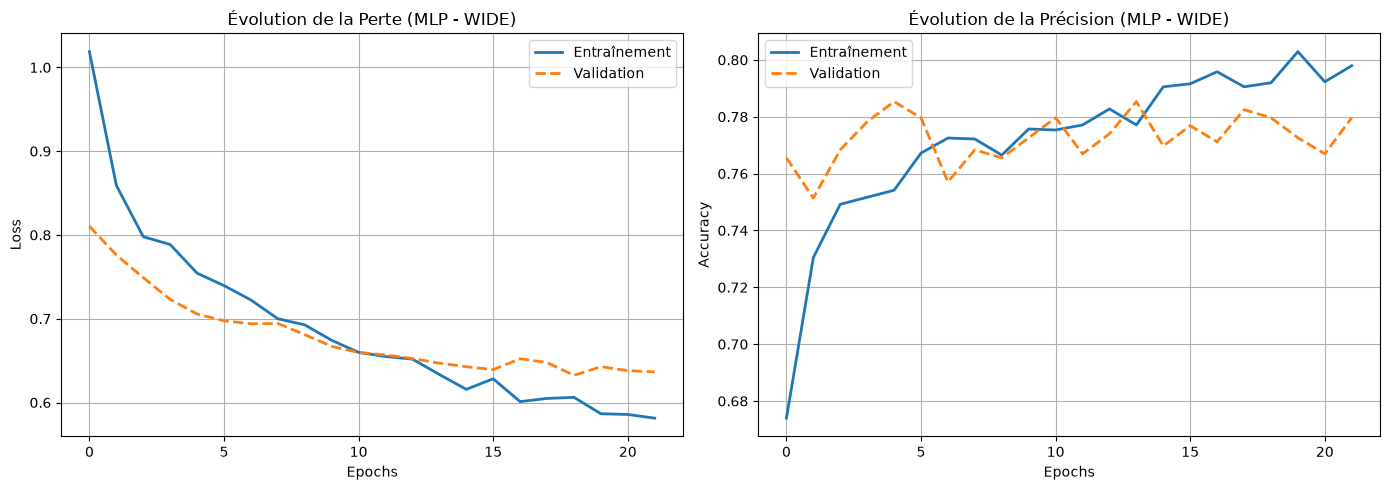

In [25]:
plot_learning_curves(history_wide, model_name="MLP - WIDE")

#### 4c. LeakyReLU

LeakyReLU laisse passer une toute petite pente pour les valeurs négatives (définie par le paramètre alpha, souvent réglé à 0.01 par défaut)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LeakyReLU, Input

model_leaky = Sequential([
    Input(shape=(X_train_pca.shape[1],)),
    Dense(64),
    LeakyReLU(negative_slope=0.01),
    Dropout(0.3),
    
    Dense(32),
    LeakyReLU(negative_slope=0.01),
    Dropout(0.2),
    
    Dense(3, activation='softmax') # La couche de sortie reste en softmax pour la classification multiclasse
])

model_leaky.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_leaky = model_leaky.fit(
    X_train_pca, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    verbose=0
)

/home/philippe/work-plateforme/05-ann-playground/.venv/lib/python3.13/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


## 5.  Choix d'hyperparemeters

1. Architecture du réseau (Capacité du modèle)
    - Le nombre de couches cachées (Profondeur) : Ajouter ou supprimer des couches pour ajuster la complexité de la cartographie que le réseau peut apprendre.
    - Le nombre de neurones par couche (Largeur) : Modifier la dimension des couches (par exemple, passer de 64 à 128 ou 256 neurones) pour donner plus ou moins de « mémoire » au modèle.
    - Les fonctions d'activation : Tester des alternatives à ReLU (comme LeakyReLU ou ELU) pour éviter le problème des neurones morts et lisser les gradients.

2. Régularisation (Contrôle de l'overfitting)
    - Le taux de Dropout : Ajuster la proportion de neurones désactivés aléatoirement à chaque étape (ex: passer de 0.3 à 0.4 ou 0.5 sur les couches denses).
    - La régularisation des poids (L1 / L2) : Jouer sur la pénalité de coût (comme le kernel_regularizer=l2(0.001)) pour forcer les poids du réseau à rester de petites valeurs et limiter la sur-mémorisation.
    - L'ajout de Batch Normalization : Insérer des couches de normalisation par lot pour stabiliser et accélérer l'apprentissage entre les couches.

3. Optimisation et Entraînement
    - Le taux d'apprentissage (Learning Rate - LR) : C'est souvent l'hyper-paramètre le plus critique. S'il est trop haut, l'apprentissage diverge ; s'il est trop bas, le modèle stagne. (Valeurs courantes : 0.001, 0.0005, 0.0001).
    - Le choix de l'optimiseur : Comparer Adam (souvent par défaut et très efficace) avec d'autres choix comme RMSprop ou SGD (Descente de gradient stochastique) couplé à du Momentum.
    - La taille des batchs (Batch Size) : Modifier le nombre d'exemples vus avant chaque mise à jour des poids (ex: 16, 32, 64, 128). Des batchs plus petits introduisent du bruit bénéfique pour la généralisation, tandis que des batchs plus grands accélèrent le calcul par époque.

4. Stratégie d'arrêt et de dynamique
    - Les paramètres de l'Early Stopping : Ajuster le seuil de patience (ex: 3, 5 ou 10 epochs) et la métrique surveillée (val_loss ou val_accuracy).
    - Le Learning Rate Scheduler : Mettre en place une baisse progressive du taux d'apprentissage au fil des epochs (par exemple, le diviser par 2 si la validation ne s'améliore plus) pour affiner les derniers réglages de poids.

5. En amont (Prétraitement et Données)
    - Le nombre de composantes de la PCA : Tu as fixé la PCA à 30 dimensions (retenant 95% de la variance). Tu pourrais tester d'ajuster ce nombre (ex: 20 ou 40) pour voir si cela impacte la performance de classification, en particulier sur la classe Enrolled.